In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import joblib
import gc
import numpy as np
from slum_segmentation import helper_functions, ml_dataset, np_dataset
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, jaccard_score

In [3]:
def shuffle_set(x, y, rng):
    permutation = rng.permutation(len(y))
    return x[permutation], y[permutation]
    
rng = np.random.default_rng(42)

# Load the best random forest model, evaluated based on previous `04` and `05` notebook experiments
# Model: Random forest 50 trees 60 max depth

In [4]:
rf = joblib.load("../models/random_forest/random_forest_50_60_depth.joblib")

# INITIAL EVALUATION ON TEST DATA WITH DEFAULT (50%) THRESHOLD

In [5]:
x_test, y_test = ml_dataset.cities.combined.get_test_data()
x_test, y_test = shuffle_set(x_test, y_test, rng)

In [6]:
y_pred = rf.predict(x_test)
test_results = helper_functions.evaluate_metrics(y_test, y_pred)
print(test_results.to_string())

        IoU (Jaccard) Precision  Recall F1-Score
Class 0         90.4%    98.76%  91.44%   94.96%
Class 1        43.42%    46.54%  86.62%   60.55%


# Visualize predictions

In [ ]:
p1 = np.load("../data/machine_learning_splits/p1.npy")
p99 = np.load("../data/machine_learning_splits/p99.npy")

In [ ]:
for city in vars(np_dataset.cities).values():
    image = city.get_image()
    mask = city.get_mask()

    print(city.name)
    prediction = helper_functions.visualize_prediction(rf, image, mask, p1, p99)

# Find best probability threshold using validation data. Use informal class IoU score for comparison

In [7]:
x_val, y_val = ml_dataset.cities.combined.get_val_data()
y_pred_probabilities = rf.predict_proba(x_val)[:, 1]

for threshold_int in range(50, 101, 5):
    threshold = float(threshold_int)/100
    y_pred = (y_pred_probabilities >= threshold).astype(np.uint8)
    validation_results = helper_functions.evaluate_metrics(y_val, y_pred)
    informal_iou = validation_results["IoU (Jaccard)"]["Class 1"]
    print(f"threshold: {threshold:.2f}, informal class IoU: {informal_iou}")

threshold: 0.50, informal class IoU: 43.45%
threshold: 0.55, informal class IoU: 45.65%
threshold: 0.60, informal class IoU: 47.57%
threshold: 0.65, informal class IoU: 49.1%
threshold: 0.70, informal class IoU: 49.99%
threshold: 0.75, informal class IoU: 49.82%
threshold: 0.80, informal class IoU: 48.27%
threshold: 0.85, informal class IoU: 44.51%
threshold: 0.90, informal class IoU: 37.32%
threshold: 0.95, informal class IoU: 22.79%
threshold: 1.00, informal class IoU: 0.01%


# Evaluate on validation data with new threshold

In [8]:
y_pred = (y_pred_probabilities >= 0.7).astype(np.uint8)
validation_results = helper_functions.evaluate_metrics(y_val, y_pred)
print(validation_results.to_string())

        IoU (Jaccard) Precision  Recall F1-Score
Class 0        93.93%    97.57%  96.18%   96.87%
Class 1        49.99%     61.9%   72.2%   66.65%


# Visualize predictions with best threshold

capetownsmall


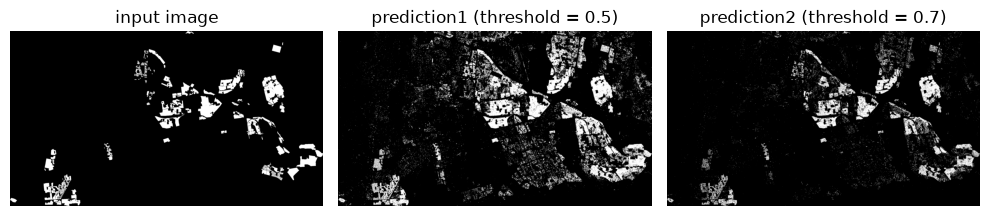

eldaein


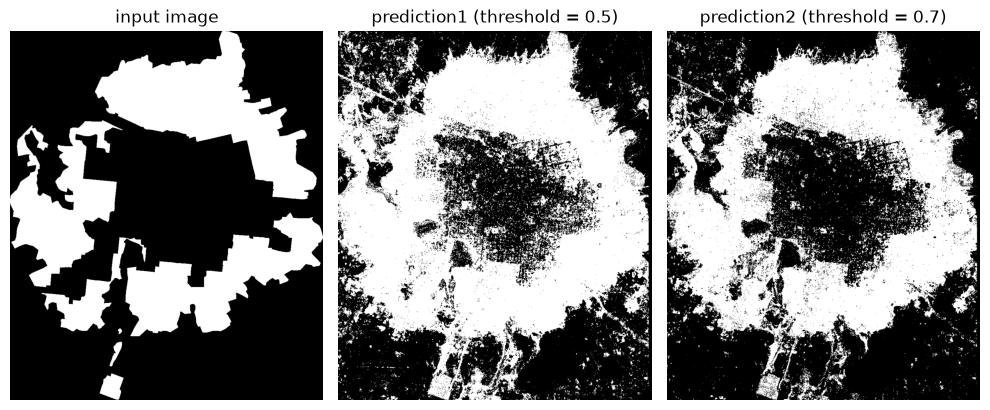

elgeneina


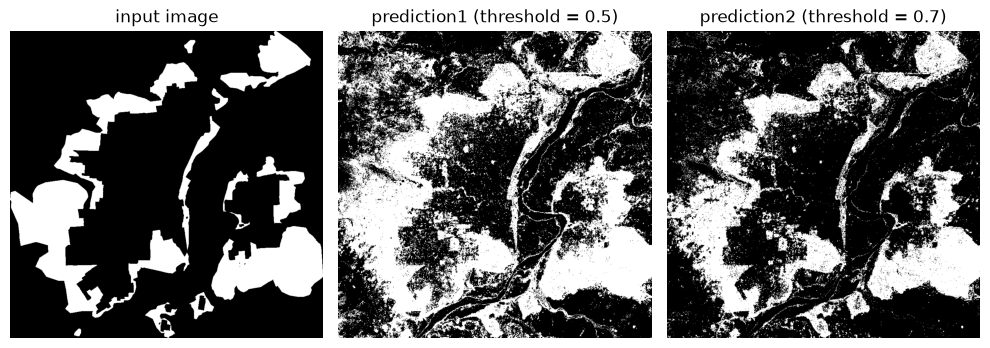

kianda


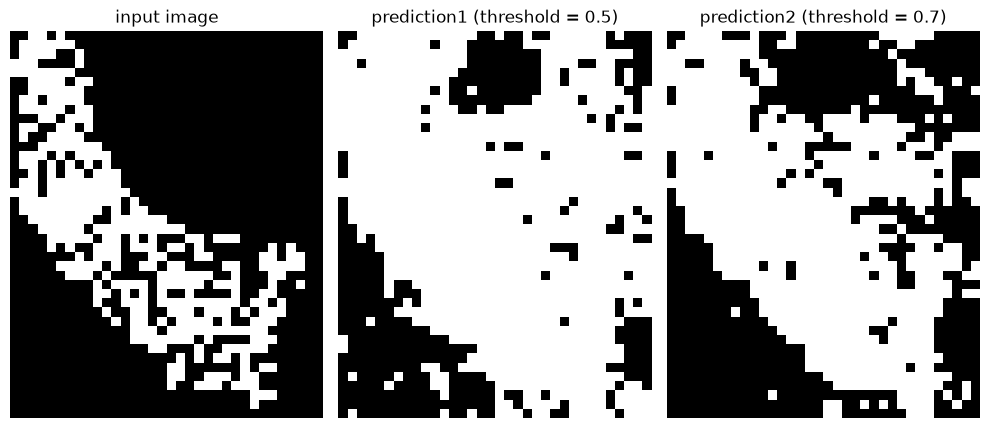

kibera


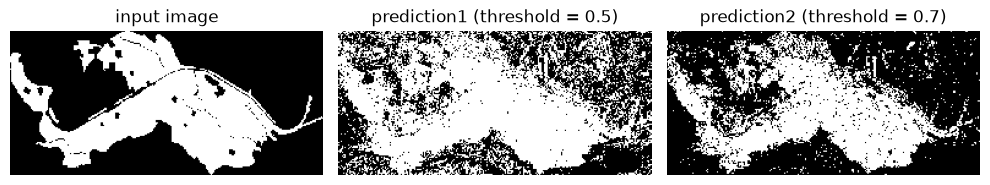

lower


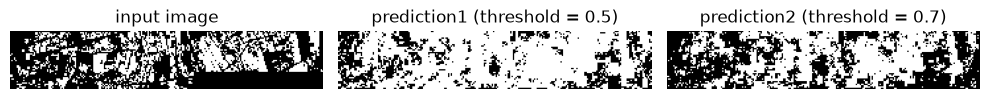

makoko


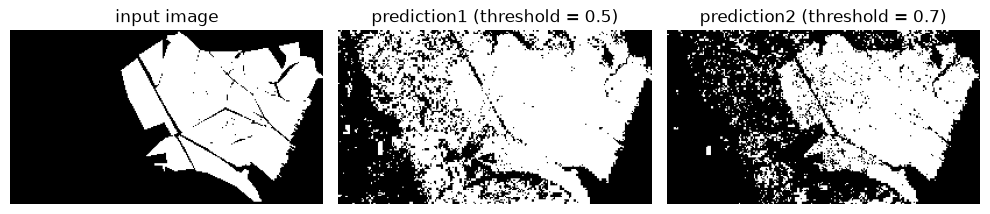

medellin


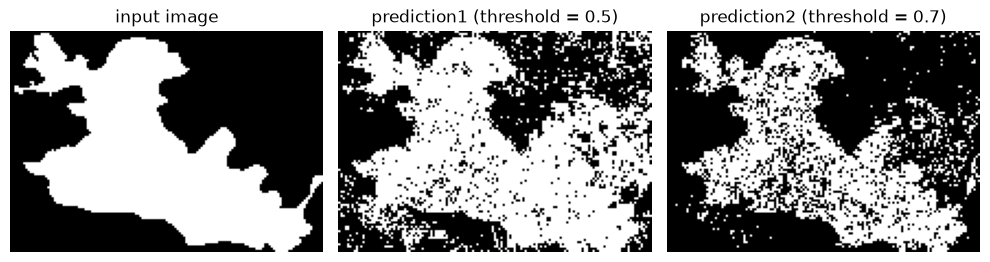

mumbai


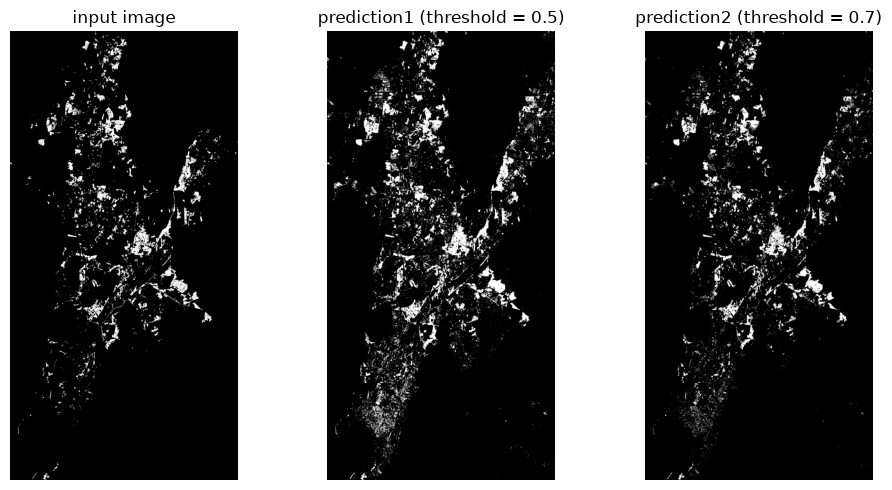

In [9]:
best_threshold = 0.70
for city in vars(np_dataset.cities).values():
    image = city.get_image()
    mask = city.get_mask()

    print(city.name)
    prediction = helper_functions.compare_custom_threshold_predictions(rf, image, mask, p1, p99, 0.5, best_threshold)

# FINAL EVALUATION ON TEST DATA WITH BEST THRESHOLD (70%)

In [10]:
x_test, y_test = ml_dataset.cities.combined.get_test_data()
x_test, y_test = shuffle_set(x_test, y_test, rng)

In [11]:
y_pred_probabilities = rf.predict_proba(x_test)[:, 1]
y_pred = (y_pred_probabilities >= 0.7).astype(np.uint8)
test_results = helper_functions.evaluate_metrics(y_test, y_pred)
print(test_results.to_string())

        IoU (Jaccard) Precision  Recall F1-Score
Class 0        93.95%    97.58%   96.2%   96.88%
Class 1        50.09%    62.04%  72.23%   66.75%


Analysis:

1. As seen from the results in notebook 05, the model made alot of false positive predictions leading to low model precision. As such, I used the validation data to find the best possible probability threshold for my best model, which was calculated to be `70%`. The threshold comparison visualizations reveal a much better predicted mask for cities when the best threshold is used. Furthermore, using the `70%` threshold improved test set `IoU` by `6.67%` and `F1` by `6.2%`, which is a significant improvement.

2. Forcing the model to be more strict by raising the threshold helps remove many false positives and improves overall `IoU` and `F1` score. A threshold of `70%` provides the best results:
```
Validation data results:
        IoU (Jaccard) Precision  Recall F1-Score
Class 0        93.93%    97.57%  96.18%   96.87%
Class 1        49.99%     61.9%   72.2%   66.65%

Test data results:
        IoU (Jaccard) Precision  Recall F1-Score
Class 0        93.95%    97.58%   96.2%   96.88%
Class 1        50.09%    62.04%  72.23%   66.75%
```